In [1]:
import pandas as pd
import numpy as np
import regex as re
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import defaultdict
from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv(r'D:\Download\doc\SK_WIDIASIH\dataset_kompas\databersih\data_waktuSMOTE.csv')

In [3]:
df.head()

,judul_berita,isi_berita,text_clean,label_kriminal,label_krim_gabungan,jenis_kriminal,prediksi_jenis_dt,motif_kejahatan,prediksi_motif_dt,hubungan_pelaku_korban,prediksi_hubungan_dt,karakteristik_kejahatan,prediksi_karakteristik_dt,waktu,prediksi_waktu_dt
0,Bocah yang Jasadnya Terbungkus Sarung Tewas Di...,"JAKARTA, KOMPAS.com - Pasangan pengemis bernam...",pasangan pengemis bernama sinta dewi 22 aidil ...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Saling Kenal,Saling Kenal,Impulsif/Spontan,Impulsif/Spontan,Malam/Dini Hari,Malam/Dini Hari
1,Orangtua Bocah Tewas dalam Sarung Sering Aniay...,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidi...",sinta dewi 22 aidil zacky rahman 19 pengemis d...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui,Tidak Kenal/Tidak Diketahui,Premeditasi/Terencana,Premeditasi/Terencana,Malam/Dini Hari,Malam/Dini Hari
2,Orangtua Bocah Tewas dalam Sarung Aniaya Anakn...,"JAKARTA, KOMPAS.com - Dua pengemis bernama Sin...",pengemis bernama sinta dewi 22 aidil zacky rah...,True,1,Pembunuhan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui,Tidak Kenal/Tidak Diketahui,Impulsif/Spontan,Impulsif/Spontan,Malam/Dini Hari,Malam/Dini Hari
3,Orangtua Bocah Tewas Terbungkus Sarung di Beka...,"JAKARTA, KOMPAS.com - Balita berinisial RMR (3...",balita berinisial rmr 3 ditemukan tewas terbun...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Saling Kenal,Saling Kenal,Impulsif/Spontan,Impulsif/Spontan,Malam/Dini Hari,Malam/Dini Hari
4,"Motif Orangtua Bunuh Anak di Bekasi, Emosi kar...","JAKARTA, KOMPAS.com - Polisi mengungkapkan, or...",polisi orangtua bernama sinta dewi 22 aidil za...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui,Tidak Kenal/Tidak Diketahui,Impulsif/Spontan,Impulsif/Spontan,Tidak Teridentifikasi,Tidak Teridentifikasi


In [4]:
print("Jumlah baris data:")
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

Jumlah baris data:
   Total baris data: 62792


In [5]:
jumlah_duplikasi = df.duplicated().sum()
print("Cek data duplikasi:")
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

Cek data duplikasi:
   Jumlah baris duplikat: 0


In [6]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
judul_berita                 0
isi_berita                   0
text_clean                   0
label_kriminal               0
label_krim_gabungan          0
jenis_kriminal               0
prediksi_jenis_dt            0
motif_kejahatan              0
prediksi_motif_dt            0
hubungan_pelaku_korban       0
prediksi_hubungan_dt         0
karakteristik_kejahatan      0
prediksi_karakteristik_dt    0
waktu                        0
prediksi_waktu_dt            0
dtype: int64


In [7]:
KEYWORDS = {
    'Area Privat (Hunian)': {
        'apartemen pribadi': 4, 'teras rumah': 2, 'kontrakan pelaku': 3, 'halaman rumah': 2,
        'pagar rumah': 3, 'atap rumah': 2, 'kamar mandi': 2, 'gudang rumah': 2, 'kediamannya': 6, 'rumah kontrakan': 5,
        'asrama pribadi': 3, 'kamar kost': 3, 'rumah dinas': 4, 'kebun rumah': 2, 'terjun lantai kos': 3, 'lantai kos': 3,
        'ruang tengah': 2, 'ruang tamu': 2, 'perumahan': 1, 'cctv rumah': 2, 'cctv rumahnya': 2, 'tempat tinggal': 2,
        'tinggal pelaku': 2, 'tempat pelaku': 2, 'tempat tinggal korban': 2, 'tempat korban': 2, 'kamar korban': 4, 'rumah korban': 4,
        'rumah': 2, 'kontrakan': 2, 'kos': 3, 'kost': 3, 'kediaman': 4, 'mess': 4, 'dapur': 2, 'rumah kosong': 3, 'rumah duka': 2,
        'pemukiman': 1, 'garasi': 2, 'apartemen': 5, 'paviliun': 2, 'mes': 2, 'kamar mes': 3, 'kamar anaknya': 4, 'kamar anak': 4, 'kamar': 1,
        'rumah susun': 3, 'guest house': 3, 'villa': 3, 'homestay': 3, 'ruang keluarga': 2, 'rumah kos': 3,
        'ruang makan': 2, 'ruang kerja pribadi': 3, 'ruang penyimpanan': 2, 'loteng': 2, 'basement rumah': 3,
        'depan rumah': 1, 'halaman': 1, 'alas kaki': 1, 'pekarangan': 3,
        'area parkir rumah': 2, 'hunian': 1, 'barak tinggal': 3, 'barak': 2, 'indekos': 3, 'petak huni': 3,
        'kost kostan': 2, 'kos kosan': 2, 'kamar kosan': 3, 'kontrakan petak': 3, 'rumah petakan': 3, 'kondominium': 3,
        'kondominium pribadi': 3, 'kluster': 2, 'perumahan dinas': 3, 'mess karyawan': 3, 'mes karyawan': 3,
        'kamar pribadi': 3, 'kamar tidur': 3, 'kamar utama': 3, 'kamar pembantu': 3, 'kamar art': 3,
        'toilet rumah': 2, 'toilet kos': 3, 'kamar mandi kos': 3, 'wastafel': 1, 'tempat jemuran': 2, 'ruang jemur': 2,
        'balkon rumah': 2, 'balkon kos': 3, 'tangga rumah': 2, 'tangga kos': 3, 'rumahnya': 7,
        'jendela rumah': 2, 'pintu rumah': 2, 'pekarangan rumah': 2, 'kebun belakang': 2,
        'rumah terlantar': 3, 'bangunan kosong': 3, 'kamar kosong': 3, 'kosan': 2,
    },
    'Area Institusi/Kerja': {
        'lingkungan sekolah': 2, 'area sekolah': 2, 'perguruan tinggi': 2, 'taman kanak kanak': 3, 'tk': 2, 'daycare': 3,
        'rumah tahanan rutan': 3, 'pondok pesantren': 3, 'gedung perkantoran': 2, 'rumah produksi': 2, 'atap sekolah': 4,
        'gudang tata usaha': 3, 'kantor tempatnya': 2, 'kantor': 1, 'kantor kementerian': 3, 'ruang tahanan': 2,
        'pangkalan militer': 3, 'lembaga pemasyarakatan': 3, 'kawasan industri': 2, 'markas organisasi masyarakat': 3,
        'gedung pemda': 3, 'kantor lurah': 3, 'kantor desa': 3, 'kantor pos': 3, 'ruang kerja': 2, 'kantor perusahaan': 3,
        'panti asuhan': 3, 'asrama polisi': 3, 'asrama tni': 3, 'rumah sakit': 3, 'kawasan pondok pesantren': 3,
        'gudang pabrik': 3, 'balai desa': 3, 'ruang kelas': 5, 'balai rw': 3, 'kantor kalurahan': 3,
        'ruang rapat': 2, 'area parkir': 1, 'ruang bimbingan': 3, 'dana desa': 1, 'kawasan pospes': 3,
        'tempat ibadah': 2, 'ruang rawat inap': 3, 'ruang pertemuan': 2, 'gedung arsitektur kampus': 3,
        'basarnas': 3, 'kpk': 3, 'tipikor': 2, 'kementerian': 2, 'pemprov': 2, 'rumah sakit jiwa': 4,
        'pemkot': 2, 'penampungan besi tua': 2, 'sd': 2, 'smp': 2, 'sma': 2, 'smk': 2, 'kamar rawat': 5,
        'bank': 1, 'sekolah': 1, 'kampus': 3, 'pabrik': 1, 'lapas': 2, 'kantor dinas': 2,
        'aula': 2, 'universitas': 2, 'pesantren': 2, 'madrasah': 2, 'puskesmas': 2, 'klinik': 2,
        'rutan': 2, 'kuil': 3, 'perpustakaan': 2, 'dpr': 3, 'falkutas': 2, 'igd': 3,
        'fakultas': 2, 'fbs': 3, 'unesa': 3, 'uin': 3, 'politeknik': 2, 'akademi': 2,
        'rumah tahanan negara': 3, 'rumah tahanan': 3, 'rumah singgah': 2, 'kantor konsultan': 4,
        'kamar jenazah': 3, 'kamar mayat': 3, 'kamar operasi': 3,
        'ott': 2, 'operasi tangkap tangan': 2, 'gedung merah putih': 3, 'lantai gedung kpk': 3,
    },
    'Area Terbuka/Alam': {
        'perkebunan sawit': 5, 'lahan kosong': 5, 'hutan jati': 5, 'kebun sawit': 6,
        'hutan karet': 4, 'semak semak': 5, 'tepi kali': 4, 'hutan belantara': 5, 'pinggir kali': 4, 'pematang sawah': 3,
        'wilayah laut': 3, 'wilayah perbatasan': 3, 'perkebunan': 3, 'di tepi sawah': 4, 'sawah': 2,
        'hutan': 2, 'kebun': 2, 'sungai': 2, 'pantai': 2, 'ladang': 3, 'jurang': 3, 'pohon': 2, 'petilasan': 4,
        'danau': 2, 'rawa': 3, 'makam': 3, 'kuburan': 3, 'persawahan': 3, 'kebun cokelat': 4, 'kawasan gunung': 3,
        'waduk': 3, 'bendungan': 3, 'tambak': 4, 'pematang': 3, 'alas': 3, 'gunung': 2, 'bukit': 2, 'patilasan': 4,
        'lembah': 3, 'gua': 4, 'air terjun': 3, 'muara': 3, 'pesisir': 3, 'tpu': 1, 'pemakaman': 1,
        'hutan mangrove': 5, 'taman nasional': 4, 'cagar alam': 4, 'pesisir pantai': 3,
        'kapal': 5, 'perahu': 3, 'perairan': 6, 'tengah laut': 4, 'selat': 3, 'samudera': 3, 'teluk': 3, 'atas kapal': 4,
        'hutan lindung': 4, 'padang rumput': 3, 'tebing': 3, 'hutan bakau': 4, 'lahan gambut': 4,
        'perkebunan teh': 4, 'kebun teh': 3, 'perkebunan kopi': 4, 'kebun kopi': 3, 'kebun cengkeh': 4,
        'kebun karet': 3, 'kebun singkong': 3, 'kebun pisang': 3, 'kebun jagung': 3, 'kebun tebu': 3,
        'lahan pertanian': 3, 'lahan perhutani': 4, 'tanah kosong': 3, 'tanah kas desa': 4, 'tanah terlantar': 3, 'tanah lapang': 3,
        'parit': 5, 'selokan': 3, 'got': 2, 'gorong gorong': 3, 'saluran air': 3, 'saluran irigasi': 3, 'irigasi': 3,
        'pinggir sungai': 4, 'tepi sungai': 4, 'bantaran sungai': 4, 'aliran sungai': 3, 'anak sungai': 3, 'dasar sungai': 4,
        'muara sungai': 4, 'tepi danau': 3, 'pinggir danau': 3, 'kawasan hutan': 3, 'kaki gunung': 3,
        'lereng gunung': 3, 'lereng bukit': 3, 'puncak gunung': 4, 'puncak bukit': 4,
        'pinggir pantai': 4, 'pantai lepas': 4, 'bibir pantai': 3, 'garis pantai': 3, 'tengah samudera': 4, 'muara laut': 4,
        'terumbu karang': 4, 'semak belukar': 5, 'padang ilalang': 5, 'hutan pinus': 4, 'kebun bambu': 4, 
        'rumpun bambu': 4, 'hutan kota': 2, 'hutan desa': 3, 'hutan produksi': 4, 'kebun kelapa': 3, 'kebun durian': 3, 'kebun mangga': 3, 'ladang jagung': 3,
        'area pertambangan': 4, 'lokasi tambang': 4, 'tambang pasir': 4, 'galian pasir': 4, 
        'lubang tambang': 5, 'lubang bekas tambang': 5, 'telaga': 3, 'mata air': 3, 'sendang': 3, 'embung': 3, 'kolam retensi': 3,
        'pelabuhan kecil': 3, 'tambak udang': 3, 'tambak ikan': 3, 'sawah tadah hujan': 4, 'kebun palawija': 3, 'kebun sayur': 3, 'kebun hortikultura': 3, 'kebun ketela': 3,
        'tambak garam': 3, 'tepian bendungan': 3, 'palung': 4, 'pesisir pulau': 3, 'dasar jurang': 5, 'lereng tebing': 4, 'ngarai': 4, 'bukit kapur': 4, 
        'goa kapur': 4, 'kawah': 4, 'kaki bukit': 3, 'tanah merah': 3, 'tebing curam': 3, 'jurang terjal': 3, 'lereng terjal': 3, 'mulut gua': 3, 'padang savana': 3, 'padang pasir': 3, 'gumuk pasir': 3, 'bukit pasir': 3, 'semak berduri': 3, 'tengah hutan': 3, 'dalam hutan': 3, 'hutan rimba': 3,
        'hutan tropis': 3, 'hutan lebat': 3, 'hutan adat': 4, 'hulu sungai': 3, 'hulu kali': 3, 'pinggir empang': 3, 'empang ikan': 3,
        'tengah rawa': 3, 'tepi rawa': 3, 'rawa rawa': 3, 'delta sungai': 3, 'pesisir utara': 3, 'pesisir selatan': 3, 'teluk laut': 3, 'lepas pantai': 3,
    },
    'Area Publik (Umum)': {
        'toilet umum': 3, 'wc umum': 3, 'toilet spbu': 3, 'wc spbu': 3, 'toilet stasiun': 3,
        'stasiun kereta': 2, 'bandar udara': 2, 'pangkalan ojek': 2, 'lapak perjudian': 3,
        'perlintasan sebidang': 3, 'pintu tol': 6, 'jalan raya': 1, 'rest area': 2, 'mushala': 2,
        'atas jembatan': 2, 'gang sempit': 3, 'taman bermain': 2, 'taman kota': 2, 'perjalanan': 4,
        'rel kereta': 2, 'lampu merah': 2, 'zebra cross': 3, 'pusat kota': 2, 'pertigaan': 1,
        'musala': 2, 'musholla': 2, 'musola': 2, 'masjid': 2, 'gereja': 2, 'vihara': 2, 'di dalam bus': 3, 'taksi': 1,
        'pinggir jalan': 4, 'lingkungan desa': 2, 'tempat sampah': 2, 'tawuran': 6, 'carok': 2,
        'jembatan': 5, 'bandara': 5, 'pangkalan': 5, 'lapak': 1, 'alun alun kota': 3, 'taman kota terbuka': 3, 'fasilitas sosial': 3, 'tribun stadion': 3, 'area parkir umum': 3, 'selasar gedung olahraga': 3,
        'trotoar': 2, 'halte': 3, 'stasiun': 5, 'terminal': 5, 'gang': 3, 'tol': 3, 'alun alun': 6,
        'perkampungan': 1, 'pelabuhan': 2, 'dermaga': 3, 'pertigaan jalan': 6, 'jalan': 2,
        'lapangan': 1, 'flyover': 3, 'underpass': 3, 'penyeberangan': 2, 'pulang hajatan': 2, 'dihadang pelaku': 2,
        'basement': 2, 'stadion': 2, 'gelora': 2, 'tps': 2, 'gor': 2, 'dipepet': 2,
        'taman bacaan': 2, 'penyeberangan orang': 5, 'halte busway': 3, 'titik jemput': 2,
        'area parkir terbuka': 2, 'jembatan penyeberangan': 3, 'ruang terbuka hijau': 2,
        'alun alun kabupaten': 3, 'rumah ibadah': 2, 'parkiran masjid': 4, 'jalan tol': 6,
        'perempatan': 4, 'persimpangan': 2, 'simpang jalan': 4, 'simpang': 1,
        'bahu jalan': 4, 'badan jalan': 4, 'lajur kiri': 2, 'lajur kanan': 2, 'ujung gang': 4, 'mulut gang': 5, 'mulut tol': 2,
        'gerbang tol': 3, 'jalur lambat': 2, 'jalur cepat': 2, 'jalur hijau': 2, 'boulevard': 2, 'jalur busway': 3,
        'pangkalan travel': 3, 'pangkalan bus': 3, 'pangkalan angkot': 3, 'pool bus': 3, 'pool travel': 3,
        'stasiun lrt': 3, 'stasiun mrt': 3, 'stasiun krl': 3, 'shelter bus': 3, 'dermaga penyeberangan': 3,
        'jembatan gantung': 3, 'jembatan layang': 3, 'jpo': 3, 'bypass': 2, 'halaman masjid': 2, 'halaman gereja': 2,
        'pelataran masjid': 2, 'teras masjid': 4, 'tempat wudhu': 3, 'kamar mandi masjid': 3,
        'lapangan bola': 2, 'lapangan futsal': 2, 'lapangan basket': 2, 'lapangan voli': 2, 'sirkuit': 2, 
        'area karang taruna': 2, 'melintas': 6, 'pedestrian': 2, 'kawasan pedestrian': 3, 'bilik toilet umum': 4, 'bilik wc umum': 4, 'toilet fasilitas umum': 4,
        'bak sampah publik': 3, 'tempat pembuangan akhir': 3, 'wastafel umum': 3,
        'kamar mandi umum': 5, 'toilet komunal': 3, 'wc komunal': 3, 'bilik toilet': 5, 'tempat pembuangan sementara': 3,
        'bak sampah': 2, 'tpa': 2, 'pembuangan sampah': 2, 'slot parkir': 2, 'drop zone': 3, 'loket pembayaran': 2, 'pos retribusi': 3, 
        'kolong flyover': 4, 'kolong jembatan': 4, 'bahu jalan tol': 4, 'pembatas jalan raya': 3, 'terowongan penyeberangan': 4, 'jalur pedestrian': 3,
        'lajur darurat': 3, 'rambu lalu lintas': 3, 'ujung trotoar': 3, 'ruang tunggu stasiun': 3, 'ruang tunggu terminal': 3, 'peron stasiun': 4,
        'halte angkutan umum': 4, 'shelter angkutan': 3, 'area kedatangan bandara': 3, 'area keberangkatan': 3, 'pintu keluar terminal': 3, 'pintu masuk stasiun': 3,
    },
    'Area Komersial': {
        'wedding organizer': 5, 'bioskop': 3, 'tukang jahit': 3, 'taman rekreasi': 2, 'taman wisata': 2, 'taman lansia': 2, 
        'klub malam': 4, 'ruang vip': 4, 'tempat hiburan': 3, 'doorsmeer': 4, 'fotokopi': 3, 'festival': 2, 'area konser': 3,
        'warung kopi': 3, 'tempat cuci': 3, 'pusat perbelanjaan': 3, 'warkop': 5, 'konter ponsel': 4, 'konter': 2,
        'konter hp': 4, 'tempat servis': 3, 'kamar penginapan': 7, 'gerai resto': 5, 'resto': 5, 'sirkuit balap': 3,
        'pedagang kaki lima': 3, 'panti pijat plus': 4, 'pijat tradisional': 4, 'dealer sepeda motor': 4,
        'food court': 4, 'kedai kopi': 3, 'indomaret': 4, 'alfamart': 4, 'toko emas': 4,
        'fitness center': 4, 'gerai retail': 3, 'toko kelontong': 3, 'distro': 3, 'franchise': 3, 'pusat grosir': 4,
        'klinik kecantikan': 4, 'percetakan': 3, 'dealer motor': 4, 'dealer mobil': 4, 'parkiran mall': 4, 'parkiran mal': 4,
        'tempat kursus': 3, 'mal': 3, 'warung makan': 3, 'pasar': 2, 'bilik atm': 3, 'konser': 2,
        'vendor': 3, 'agensi': 3, 'biro': 3, 'travel': 2, 'dealer': 3, 'toko sayur': 3, 'toko sayuran': 3, 'toko': 5,
        'cabang': 2, 'hotel': 5, 'penginapan': 4, 'wisma': 3, 'losmen': 3, 'resort': 4,
        'diskotik': 4, 'pub': 4, 'bar': 3, 'kedai': 2, 'bengkel': 3, 'kios': 2, 'mall': 3, 'warmindo': 3,
        'kafe': 4, 'karaoke': 7, 'warung': 4, 'minimarket': 3, 'ruko': 3, 'swalayan': 3, 'area mall': 3,
        'cafe': 4, 'plaza': 3, 'supermarket': 3, 'spa': 4, 'panti pijat': 4, 'biliar': 3,
        'angkringan': 3, 'apotek': 4, 'pegadaian': 4, 'showroom': 4, 'ruang karaoke': 7,
        'laundry': 3, 'salon': 3, 'gym': 3, 'kantin': 3, 'pujasera': 4, 'boutique': 4, 'gerai': 4,
        'lokalisasi': 4, 'eks lokalisasi': 4, 'rumah makan': 3, 'rumah potong hewan': 4,
        'penjahit': 3, 'modiste': 4, 'barbershop': 3, 'pangkas rambut': 3, 'studio foto': 4, 'tempat pencucian motor': 4,
        'tempat pencucian mobil': 4, 'car wash': 4, 'petshop': 4, 'galeri atm': 3,
        'restoran': 5, 'warung nasi': 3, 'warnas': 3, 'warteg': 3, 'depot': 3, 'depot makan': 3, 'kedai makanan': 3, 'bakso': 2,
        'mie ayam': 2, 'angkringan kopi': 3, 'kedai susu': 3, 'boba': 3, 'food truck': 4, 'dapur komersial': 4,
        'indomart': 4, 'alpamart': 4, 'alfamidi': 4, 'superindo': 4, 'hypermart': 4, 'grosir': 3,
        'toko bangunan': 3, 'toko material': 3, 'depo bangunan': 4, 'toko baju': 3, 'toko pakaian': 3,
        'toko sepatu': 3, 'toko mainan': 3, 'toko sembako': 3, 'toko buah': 3, 'toko daging': 3, 'toko obat': 3,
        'petrokimia': 4, 'pameran': 3,
        'kelab malam': 4, 'lounge': 4, 'billiard': 3, 'tempat dugem': 4, 'karaoke keluarga': 4, 'karaoke eksekutif': 4,
        'panti pijat tunas': 4, 'pijat refleksi': 4, 'sauna': 4, 'solarium': 4, 'arena ketangkasan': 4, 'wahana permainan': 4,
        'motel': 4, 'kamar hotel': 4, 'kamar wisma': 4, 'lobby hotel': 4, 'ballroom': 4,
        'spbu': 4, 'pom bensin': 4, 'pertamini': 4, 'steam motor': 4, 'steam mobil': 4, 
        'toko ban': 3, 'toko variasi': 3, 'atm': 4, 'mesin atm': 4, 
        'money changer': 4, 'tempat penukaran uang': 4, 'kantor ekspedisi': 4, 
        'gudang logistik': 4, 'agen pengiriman': 3, 'kantor kurir': 3, 'warnet': 4, 
        'game center': 4, 'rental ps': 4, 'vape store': 4, 'toko vapor': 4, 'restoran cepat saji': 4, 'warung makan lesehan': 3, 'kedai makanan minuman': 3,
        'kedai kopi modern': 3, 'warung kopi pangku': 4, 'rumah makan padang': 3,
        'pasar malam': 3, 'pasar kaget': 3, 'toko perhiasan': 4, 'toko elektronik': 3, 
        'toko jam': 3, 'toko kacamata': 3, 'optik': 3, 'kompleks pertokoan': 4, 'pusat pertokoan': 4, 'kompleks ruko': 3, 'kawasan pertokoan': 3, 'pasar swalayan': 3, 'etalase toko': 3,
        'pasar tradisional': 3, 'pusat perbelanjaan modern': 4, 'tempat hiburan malam': 4, 'salon kecantikan': 3, 'klinik kecantikan medis': 4, 'loket kasir': 3, 'bengkel resmi': 3, 'bengkel motor': 3, 'bengkel mobil': 3, 'resepsionis hotel': 4, 'lobi hotel bintang': 4, 'kamar hotel melati': 4,
    },
    'Ruang Digital/Siber': {
        'hacker': 4, 'oknum hacker': 4, 'peretasan': 7, 'diretas': 7, 'meretas': 7, 'peretas': 7,
        'ransomware': 7, 'malware': 7, 'spyware': 7, 'brute force': 7, 'ddos': 7, 'sql injection': 7,
        'deface': 7, 'sniffing': 7, 'keylogger': 4, 'remote access trojan': 7, 'rat': 4, 'backdoor': 4,
        'botnet': 4, 'dark web': 4, 'data breach': 4, 'kebocoran data': 4, 'akses ilegal': 4,
        'menyerang jaringan komputer': 4, 'hacker menyerang jaringan': 4, 
        'bandar judi online': 4, 'judi online': 2, 'judol': 2,
        'situs perjudian online': 4, 'deposit pulsa judi': 4, 'link alternatif judi': 4, 'afiliator judi': 4,
        'togel online': 4, 'mempromosikan judi daring': 5, 'promosi judi daring': 5, 'pelaku judi daring': 4,
        'live casino online': 4, 'pinjol online': 4, 'phising': 4, 'voice phishing': 5, 'skimming': 7,
        'social engineering': 4, 'soceng': 4, 'otp fraud': 4, 'catfishing': 4, 'sim swap': 4, 'bobol banking': 4,
        'carding': 4, 'phishing': 4, 'bobol m banking': 4, 'apk berbahaya': 4, 'undangan digital apk': 4,
        'kurir paket apk': 4, 'tagihan pln apk': 4, 'aplikasi robot trading': 4,
        'money mule': 4, 'doxing': 4, 'cyberbullying': 5, 'cyberstalking': 5, 'stalking digital': 4,
        'deepfake': 5, 'ai deepfake': 4, 'konten pornografi ilegal': 5, 'tindak pidana siber': 6,
        'pasal 27 ayat 3 uu ite': 4, 'terlibat judol': 5, 'keterlibatan di perjudian': 4, 'pemain judi online': 3, 'kedapatan aplikasi perjudian': 7,
        'situs taruhan': 3, 'mempromosikan judi': 4, 'bandar judi': 3,
        'penipuan online': 3, 'scam': 3, 'link palsu': 3, 'website palsu': 3, 'robot trading': 4,
        'tersangka robot trading': 3, 'bobol rekening': 4, 'rekening penampung': 3, 'jual beli akun bank': 3,
        'jual beli sim card': 3, 'hate speech': 3, 'ujaran kebencian': 3, 'hoaks': 3, 'menyebarkan bohong': 3,
        'viral medsos': 2, 'video viral': 2, 'iseng konten': 4, 'aduan konten': 3, 'pornografi': 3,
        'konten pornografi': 3, 'menyebarkan video prono': 5,
        'menyebarkan video mesumnya': 5, 'menyebarkan video mesum': 3, 'video mesum viral': 3,
        'video mesum': 3, 'berisi adegan mesum': 3, 'memputar video porno': 3, 'menyebarkan video tangkapan': 3,
        'uu ite': 3, 'ite': 3, 'uu pdp': 3, 'pse': 3, 'informasi transaksi elektronik': 3,
        'aplikasi chatting': 3, 'live streaming': 3, 'video call': 3, 'voice note': 3, 'revange porn': 3,
        'korban foto telanjang': 3, 'foto telanjang': 3, 'berkonten dewasa': 3, 'binary option': 3,
        'cyber army': 3, 'aplikasi binomo': 3, 'pidana judi online': 3, 'penyebaran bohong media': 3,
        'video pornografi anak': 3, 'cyber bullying': 3, 'binomo': 3, 'peneror panggilan video': 7,
        'panggilan video cabul': 3, 'video alat kelamin': 3, 'prostitusi online': 3, 'pembobolan dana': 3,
        'pembobolan sistem keamanan': 5, 'pencurian saldo': 3, 'peretasan sistem mobile': 3,
        'grup telegram': 3, 'grup whatsapp': 3, 'mengaku customer service': 3, 'kode aktivasi masuk': 4,
        'defacing': 3, 'akses mobile banking': 3, 'video asusila': 3, 'konten asusila': 3,
        'situs dewasa': 3, 'situs khusus dewasa': 3, 'video porno': 3, 'modus like and subscribe': 7, 'aplikasi uang digital': 3, 'menjalankan misi': 2, 'toko daringnya': 3, 'toko daring aktif': 3,
        'pencurian data pribadi': 3, 'identity theft': 2, 'pencemaran nama baik': 2,
        'pencemaran nama': 2, 'merusak nama pribadi': 2, 'pencucian uang digital': 2, 'toto gelap': 2,
        'menyerang jaringan': 2, 'menyebarkan video': 2, 'tersangka merekamnya': 2, 'pelaku sengaja merekam': 2,
        'dark system': 2, 'berita bohong': 2, 'di situs daring': 2, 'situs daring': 2, 'fraud': 2,
        'kehilangan tabungan': 2, 'rekening tak dikenal': 2, 'mengunggah video': 2, 'merekam video': 2,
        'server hos daring': 5, 'alamat ip pelaku': 5, 'log masuk ilegal': 4, 'port jaringan terbuka': 4, 'enkripsi basis data': 5, 'injeksi kode sql': 6,
        'peretasan pelayan web': 5, 'sertifikat ssl palsu': 4, 'dompet digital penampung': 4, 'transaksi aset kripto': 4, 'alamat dompet kripto': 4,
        'saldo akun digital': 3, 'pencucian uang kripto': 4, 'buku kas digital': 3, 'tautan unduhan apk': 5, 'skrip malware berbahaya': 5, 'ekstensi berkas palsu': 4,
        'halaman phising bank': 5, 'domain situs judi': 4, 'server judi daring': 5,
    },
}

COMPILED_KEYWORDS = {
    category: {
        kw: (re.compile(r'\b' + re.escape(kw) + r'\b'), weight)
        for kw, weight in kw_dict.items()
    }
    for category, kw_dict in KEYWORDS.items()
}

CLASS_PRIORITY = [
    'Ruang Digital/Siber',
    'Area Privat (Hunian)',
    'Area Terbuka/Alam',
    'Area Komersial',
    'Area Publik (Umum)',
    'Area Institusi/Kerja'
]

ARREST_MARKERS = [
    'ditangkap', 'dibekuk', 'diringkus', 'diamankan', 'ditahan ke',
    'dicokok', 'diciduk', 'digrebek', 'disergap', 'dijemput paksa',
    'ditangkap petugas', 'ditangkap polisi', 'berhasil diamankan', 'dievakuasi ke',
    'dibawa ke', 'korban dibawa ke', 'dilarikan ke', 'digiring ke', 'melarikan diri ke',
    'diamankan ke', 'ditahan ke', 'dirawat di', 'korban dirawat di',
    'ditahan di', 'diamankan di', 'meringkuk di', 'dievakuasi di'
]

SCENE_OVERRIDE_MARKERS = [
    'lokasi kejadian', 'tkp', 'tempat kejadian perkara',
    'di tempat kejadian', 'saat kejadian', 'ketika kejadian',
    'di lokasi', 'di tempat', 'di tkp',
    'di area kejadian', 'di kawasan tersebut', 'di sekitar lokasi',
    'di tempat terpisah', 'di kediaman pelaku', 'di rumah korban',
    'sewaktu kejadian', 'pelecehan', 'penikaman',
    'saat penggerebekan', 'saat penangkapan', 'saat kejadian berlangsung',
    'pasca kejadian', 'setelah kejadian', 'beberapa saat setelah kejadian',
    'di saat bersamaan', 'pembunuhan', 'penembakan', 'penusukan', 'pembacokan',
    'penganiayaan', 'pengeroyokan', 'penghilangan nyawa',
    'pembunuhan berencana', 'aksi pembunuhan', 'tindak pidana pembunuhan',
    'penganiayaan berat', 'penganiayaan hingga tewas', 'pembunuhan sadis',
    'kasus pembunuhan', 'ditemukan tewas', 'ditemukan meninggal dunia',
    'meregang nyawa', 'tewas bersimbah darah', 'tewas di tangan pelaku',
    'dihabisi pelaku', 'kejadiannya', 'peristiwa', 'aksi', 'terjadi aksi', 'kejadian',
    'peristiwa pembunuhan', 'dugaan pembunuhan',
    'penemuan jasad', 'penemuan mayat', 'saat aksi pembunuhan', 'eksekusi korban',
    'penyerangan', 'pencabulan', 'pelecehan seksual', 'kekerasan seksual', 'pemerkosaan',
    'perbuatan cabul', 'tindak asusila', 'tindak pencabulan', 'kasus pencabulan',
    'dugaan pencabulan', 'persetubuhan di bawah umur',
    'penodongan', 'penodongan senjata', 'penodongan sajam', 'perampokan',
    'pembegalan', 'perampasan', 'pemerasan', 'perampasan dengan kekerasan',
    'aksi penodongan', 'tindak pidana perampokan'
]

_ARREST_CLAUSE_PATTERN = re.compile(
    r'\b(' + '|'.join(re.escape(m) for m in ARREST_MARKERS) + r')\b'
    r'[^.,;!?]*?'
    r'(?=[.,;!?]|$|\bkemudian\b|\bsetelah\b|\blalu\b|\bdan\b)',
    flags=re.IGNORECASE
)


def strip_arrest_clauses(text):
    if not text:
        return text
    def _replacer(match):
        clause = match.group(0)
        if any(marker in clause for marker in SCENE_OVERRIDE_MARKERS):
            return clause  
        return ' ' 

    return _ARREST_CLAUSE_PATTERN.sub(_replacer, text)


def classify_location(text):
    if not text or not isinstance(text, str):
        return "Tidak Teridentifikasi"

    text = text.lower()
    scoring_text = strip_arrest_clauses(text)

    forensic_context = ["pembongkaran makam", "pembongkaran tpu", "autopsi", "bertakziah", "warisan"]
    apply_forensic_penalty = any(ctx in scoring_text for ctx in forensic_context)

    locus_privat_markers = ["di rumahnya", "di dalam rumah", "di rumah korban"]
    has_locus_privat = any(marker in scoring_text for marker in locus_privat_markers)

    scores = {}

    for category, kw_dict in COMPILED_KEYWORDS.items():
        max_weight = 0
        total_score = 0
        first_pos = float('inf')
        match_count = 0

        for kw, (pattern, weight) in kw_dict.items():
            if kw not in scoring_text:
                continue

            if category == 'Area Terbuka/Alam' and kw in ['tpu', 'makam', 'tanah'] and apply_forensic_penalty:
                weight = 1

            matches = [m.start() for m in pattern.finditer(scoring_text)]

            if matches:
                match_count += len(matches)
                total_score += weight * len(matches)
                if weight > max_weight:
                    max_weight = weight
                if matches[0] < first_pos:
                    first_pos = matches[0]

        if category == 'Area Privat (Hunian)' and has_locus_privat:
            max_weight = max(max_weight, 4)
            total_score += 5

        if match_count > 0:
            scores[category] = {
                'max_weight': max_weight,
                'total_score': total_score,
                'first_pos': first_pos
            }

    if not scores:
        return "Tidak Teridentifikasi"

    def sorting_key(item):
        category, data = item
        priority_idx = CLASS_PRIORITY.index(category) if category in CLASS_PRIORITY else 99
        return (
            -data['max_weight'],
            priority_idx,
            -data['total_score'],
            data['first_pos']
        )

    sorted_candidates = sorted(scores.items(), key=sorting_key)
    return sorted_candidates[0][0]

tqdm.pandas()
df['lokasi'] = df['text_clean'].progress_apply(classify_location)

  0%|          | 0/62792 [00:00<?, ?it/s]

In [8]:
dist_kriminal = pd.DataFrame({
    'Jumlah': df['lokasi'].value_counts(dropna=False),
    'Persentase (%)': (df['lokasi'].value_counts(dropna=False, normalize=True) * 100).round(2)
})

print("=== DISTRIBUSI LOKASI ===")
print(dist_kriminal)

=== DISTRIBUSI LOKASI ===
                       Jumlah  Persentase (%)
lokasi                                       
Area Privat (Hunian)    18442           29.37
Area Institusi/Kerja    10362           16.50
Area Publik (Umum)      10349           16.48
Area Komersial           9576           15.25
Tidak Teridentifikasi    5050            8.04
Ruang Digital/Siber      4748            7.56
Area Terbuka/Alam        4265            6.79


## CEK

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[df['label_kriminal'] == True].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['lokasi']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [ ]:
target_indices = [46168, 47879, 51373, 21135, 48809, 51881, 46103, 
                  57306, 49708, 52019, 2189, 14618, 57400, 33052, 
                  15590, 22587, 25119, 113, 49836, 12450, 14573, 
                  42652, 59457, 36268, 24685, 22494, 11402, 62917, 15533, 44711, 30745
]

for idx in target_indices:
    if idx in df.index:
        print(f"INDEX              : {idx}")
        print(f"LABEL LOKASI       : {df.loc[idx, 'lokasi']}")
        print(f"BERITA ISI         : \n{df.loc[idx, 'text_clean']}")
        print("\n" + "="*80 + "\n")
    else:
        print(f"Index {idx} tidak ditemukan dalam DataFrame.")

## ML

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text_clean"],
    df["lokasi"],
    test_size=0.2,
    random_state=42,
    stratify=df["lokasi"],
)

In [ ]:
URUTAN_KELAS = sorted(y_train.unique())

tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=25000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_tfidf, y_train
)

In [12]:
model_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
model_gini.fit(X_train_balanced, y_train_balanced) 
pred_test_gini = model_gini.predict(X_test_tfidf)

model_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
model_entropy.fit(X_train_balanced, y_train_balanced)  
pred_test_entropy = model_entropy.predict(X_test_tfidf)

pred_combined_multiclass = np.where(
    pred_test_gini == pred_test_entropy, 
    pred_test_gini, 
    'Tidak_Sama'
)

 EVALUASI: MODEL GINI

[1] CLASSIFICATION REPORT:
                       precision    recall  f1-score   support

 Area Institusi/Kerja       0.77      0.79      0.78      2072
       Area Komersial       0.75      0.73      0.74      1915
 Area Privat (Hunian)       0.84      0.81      0.83      3689
   Area Publik (Umum)       0.79      0.76      0.77      2070
    Area Terbuka/Alam       0.59      0.64      0.62       853
  Ruang Digital/Siber       0.73      0.75      0.74       950
Tidak Teridentifikasi       0.62      0.69      0.66      1010

             accuracy                           0.76     12559
            macro avg       0.73      0.74      0.73     12559
         weighted avg       0.76      0.76      0.76     12559


[2] CONFUSION MATRIX:


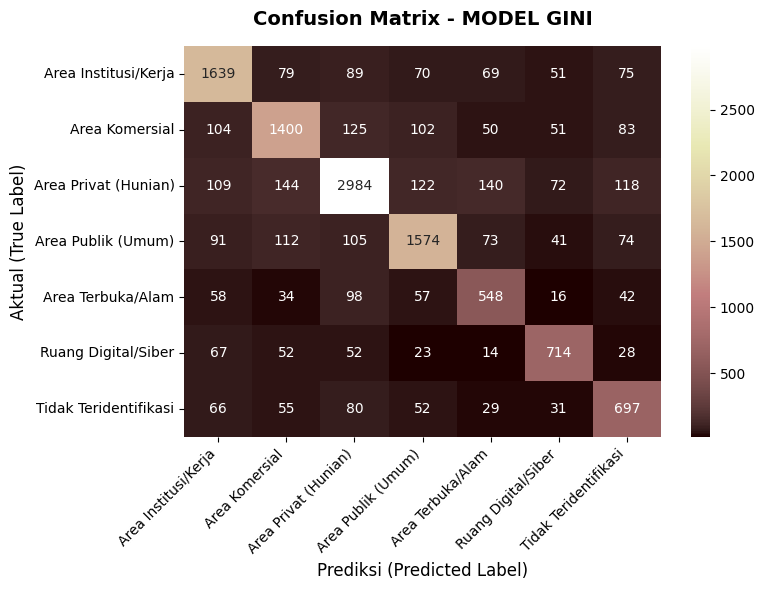


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 EVALUASI: MODEL ENTROPY

[1] CLASSIFICATION REPORT:
                       precision    recall  f1-score   support

 Area Institusi/Kerja       0.73      0.76      0.74      2072
       Area Komersial       0.69      0.67      0.68      1915
 Area Privat (Hunian)       0.84      0.79      0.82      3689
   Area Publik (Umum)       0.73      0.71      0.72      2070
    Area Terbuka/Alam       0.54      0.54      0.54       853
  Ruang Digital/Siber       0.70      0.72      0.71       950
Tidak Teridentifikasi       0.55      0.65      0.59      1010

             accuracy                           0.72     12559
            macro avg       0.68      0.69      0.69     12559
         weighted avg       0.73      0.72      0.72     12559


[2] CONFUSION MATRIX:


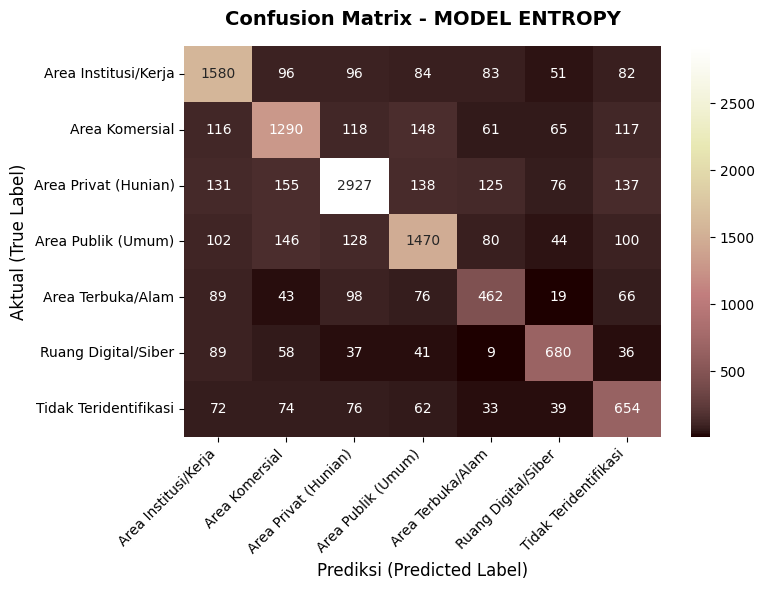


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 EVALUASI: MODEL GABUNGAN (LOGIKA AND)

[1] CLASSIFICATION REPORT:
                       precision    recall  f1-score   support

 Area Institusi/Kerja       0.86      0.65      0.74      2072
       Area Komersial       0.89      0.58      0.70      1915
 Area Privat (Hunian)       0.92      0.70      0.79      3689
   Area Publik (Umum)       0.88      0.62      0.73      2070
    Area Terbuka/Alam       0.85      0.45      0.59       853
  Ruang Digital/Siber       0.85      0.61      0.71       950
Tidak Teridentifikasi       0.84      0.55      0.67      1010
           Tidak_Sama       0.00      0.00      0.00         0

             accuracy                           0.63     12559
            macro avg       0.76      0.52      0.62     12559
         weighted avg       0.88      0.63      0.73     12559


[2] CONFUSION MATRIX:


C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r

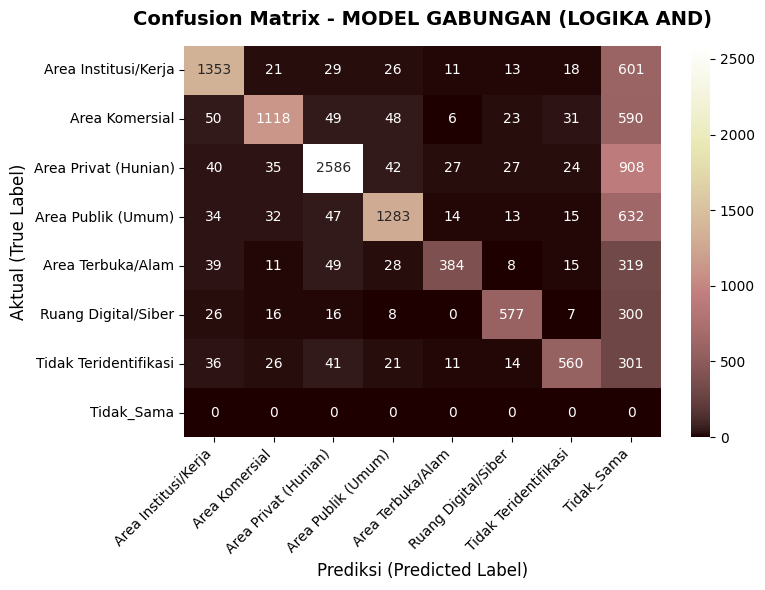


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx



In [15]:
eval_dict = {
    'MODEL GINI': pred_test_gini,
    'MODEL ENTROPY': pred_test_entropy,
    'MODEL GABUNGAN (LOGIKA AND)': pred_combined_multiclass,}

for model_name, pred in eval_dict.items():
    print("=" * 70)
    print(f" EVALUASI: {model_name}")
    print("=" * 70)

    print("\n[1] CLASSIFICATION REPORT:")
    print(classification_report(y_test, pred))

    print("\n[2] CONFUSION MATRIX:")
    labels = sorted(list(set(y_test) | set(pred)))
    cm = confusion_matrix(y_test, pred, labels=labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,  
        fmt='d',  
        cmap='pink',  
        xticklabels=labels, 
        yticklabels=labels,  
        cbar=True,  
    )

    plt.title(
        f'Confusion Matrix - {model_name}',
        fontsize=14,
        fontweight='bold',
        pad=15,
    )
    plt.xlabel('Prediksi (Predicted Label)', fontsize=12)
    plt.ylabel('Aktual (True Label)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()  
    print("\n" + "x" * 70 + "\n")

In [14]:
df_hasil_lokasi = df.copy()
X_clean_tfidf = tfidf.transform(df_hasil_lokasi['text_clean'])
pred_gini = model_gini.predict(X_clean_tfidf)
pred_entropy = model_entropy.predict(X_clean_tfidf)

df_hasil_lokasi['prediksi_lokasi_dt'] = np.where(
    pred_gini == pred_entropy, 
    pred_gini, 
    'Tidak_Sama'
)
df_hasil_lokasi = df_hasil_lokasi[df_hasil_lokasi['prediksi_lokasi_dt'] != 'Tidak_Sama']

nama_file_final = "data_lokasiSMOTE_finalFPG.csv"
df_hasil_lokasi.to_csv(nama_file_final, index=False)

print(f" Selesai! Data berhasil difilter.")
print(f" Sisa data bersih tersimpan: {len(df_hasil_lokasi)} baris di file '{nama_file_final}'")

 Selesai! Data berhasil difilter.
 Sisa data bersih tersimpan: 59141 baris di file 'data_lokasiSMOTE_finalFPG.csv'
